# Assignment 2: Double Well Tunneling

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import scipy.sparse as sp

plt.rcParams.update({"font.size": 13,
    "figure.figsize": (6.2, 3.3), "figure.dpi": 100,
    "figure.constrained_layout.use": True})

## Creating the Grid

Use $m=\hbar=1$ and 600 intervals on $[-4,4]$.

In [2]:
ALPHA = 0.3 + 102 / 5000
HBAR = 1
BOXSIZE = 8
ND = 600
DELTAX = BOXSIZE / ND
XMIN = 1 / np.sqrt(ALPHA)
x = np.linspace(-BOXSIZE / 2, BOXSIZE / 2, ND + 1)
print("Positions:", x.size, "Spacing:", DELTAX)

Positions: 601 Spacing: 0.013333333333333334


## Following the Wave Packet Across a Barrier

$$
V(x)=\alpha x^4-2x^2+\frac{1}{\alpha}.
$$

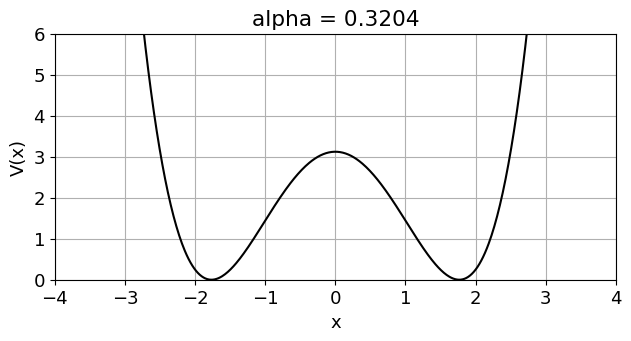

In [3]:
@njit
def V(x, alpha):
    return alpha * x**4 - 2 * x**2 + 1 / alpha

alpha_view = ALPHA
fig, ax = plt.subplots()
ax.plot(x, V(x, alpha_view), color="black")
ax.set(xlabel="x", ylabel="V(x)",
       xlim=(-4, 4), ylim=(0, 6),
       title=f"alpha = {alpha_view}")
ax.grid(True) 
plt.show()

## Near each minimum

Expand around either minimum through second order. Since $V=V^{\prime}=0$ and $V^{\prime\prime}=8$ there, the potential is locally quadratic:

$$
V_\pm(x)=4(x\mp x_{\min})^2,
$$

with $x_{\min}=1/\sqrt{\alpha}$

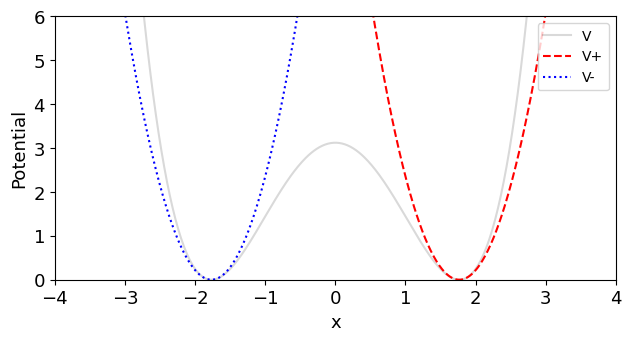

In [4]:
@njit
def V_plus(x, alpha): 
    return 4 * (x - 1 / np.sqrt(alpha))**2
@njit
def V_minus(x, alpha):
    return 4 * (x + 1 / np.sqrt(alpha))**2

def plot_potentials(ax, v_color, posv_color, negv_color):
    ax.plot(x, V(x, ALPHA), color=v_color)
    ax.plot(x, V_plus(x, ALPHA), "--", color=posv_color)
    ax.plot(x, V_minus(x, ALPHA), ":", color=negv_color)
    ax.set(ylabel="Potential", ylim=(0, 6),
           zorder=0)
    ax.legend(["V", "V+", "V-"],
              loc="upper right", fontsize=10)
    
x_window = (-4, 4)
fig, ax = plt.subplots()

plot_potentials(ax, v_color = ('black', 0.15), posv_color='red', negv_color='blue') # can you guess how to colors work here?
ax.set(xlabel="x", xlim=x_window)
plt.show()

## The initial wavefunction

We approximate the state as a ground state oscillator, with $\omega=2\sqrt{2}$ from $\tfrac12\omega^2=4$:

$$
\psi(x)=\left(\frac{\omega}{\pi}\right)^{1/4}
\exp\left[-\frac{\omega}{2}(x-x_c)^2\right],
$$

which is just a gaussian.

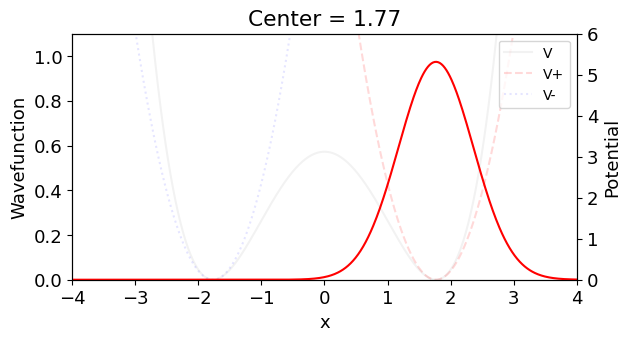

In [5]:
OMEGA = np.sqrt(8)
@njit
def func_psi_0(x, x_start):
    return (OMEGA / np.pi)**0.25 * np.exp(
        -OMEGA * (x - x_start)**2 / (2 * HBAR))

psi_0 = func_psi_0(x, XMIN)
center = XMIN

fig, ax = plt.subplots()
ax.plot(x, func_psi_0(x, center), color='red')
ax.set(xlabel="x", ylabel="Wavefunction",
       zorder=1, xlim=(-4, 4), ylim=(0, 1.1),
       title=f"Center = {center:.2f}")

ax.patch.set_visible(False)
plot_potentials(ax.twinx(), v_color = ('black', .05), posv_color=('red', .15), negv_color=('blue', .1))
plt.show()

## Problem A: Path-Integral Tunneling

Evolve the Gaussian using the full double-well potential. As in Assignment 1, the short-time propagator carries amplitude from $x_a$ to $x_b$:

$$
\tilde{\mathcal K}(x_b,\Delta t;x_a,0)=
\exp\left[i\left(\frac{(x_b-x_a)^2}{2\Delta t}
-V\left(\frac{x_a+x_b}{2}\right)\Delta t\right)\right].
$$

In [6]:
@njit
def func_K(x_a, x_b, dt, alpha):
    kinetic = 0.5 * (x_b - x_a)**2 / dt
    potential = V((x_a + x_b) / 2, alpha) * dt
    return np.exp(1j * (kinetic - potential))

### From the propagator to the next state

Add the complex amplitudes from every starting position. On the grid, the integral becomes a weighted sum:

$$
\begin{aligned}
\psi(x_b,t+\Delta t)&\approx\int \mathcal K(x_b,x_a;\Delta t)\psi(x_a,t)\,dx_a,\\
\psi_i(t+\Delta t)&\approx\Delta x\sum_j K_{ij}\psi_j(t).
\end{aligned}
$$

### Build the matrix

Each column starts at one position; each row arrives at one position. Use the assignment's $\Delta t=\pi/128$ for the evolution.

In [7]:
@njit
def build_kernel(x, dt, alpha):
    kernel = np.zeros((x.size, x.size),
                      dtype=np.complex64)
    for i in range(x.size):
        for j in range(x.size):
            kernel[i, j] = func_K(
                x[j], x[i], dt, alpha)
    return kernel.astype(np.complex128)

DELTAT = np.pi / 128
K_dt = build_kernel(x, DELTAT, ALPHA)
print("Kernel shape:", K_dt.shape)

Kernel shape: (601, 601)


### Take a step and inspect it

The grid sum is a matrix–vector product. Normalize because our kernel omits the scalar prefactor.

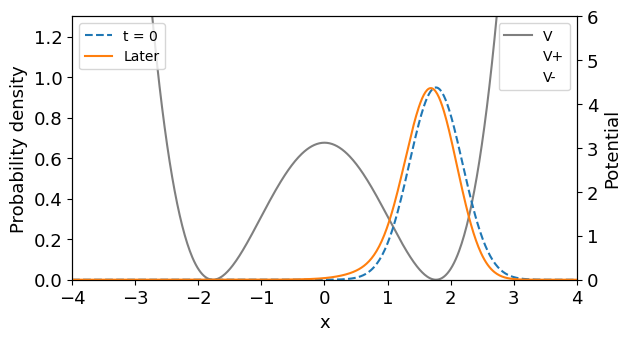

In [8]:
@njit
def step(state, kernel, dx):
    updated = dx * (kernel @ state)
    norm = dx * np.sum(np.abs(updated)**2)
    return updated / np.sqrt(norm)
    
@njit
def evolve(state, kernel, dx, nt):
    psi = np.empty((nt + 1, state.size),
                   dtype=np.complex128)
    psi[0] = state
    for n in range(nt):
        psi[n + 1] = step(psi[n], kernel, dx)
    return psi

steps_view = 20
psi_view = evolve(psi_0.astype(np.complex128),
                  K_dt, DELTAX, steps_view)[-1]
    
fig, ax = plt.subplots()
ax.plot(x, np.abs(psi_0)**2, "--", label="t = 0")
ax.plot(x, np.abs(psi_view)**2, label="Later")
ax.set(xlabel="x", ylabel="Probability density",
       zorder=1, xlim=(-4, 4), ylim=(0, 1.3))
ax.legend(loc="upper left", fontsize=10)
ax.patch.set_visible(False)

plot_potentials(ax.twinx(), v_color = ('black', .5), posv_color=('red', 0), negv_color=('blue', 0))
plt.show()

### (i) **Run and Plot**

Run to $T=20\pi$. The mean is the probability-weighted average of position:

$$
\langle x\rangle(t)\approx\Delta x\sum_i x_i|\psi(x_i,t)|^2.
$$

In [9]:
T0 = 45 * np.pi
NT = int(T0 / DELTAT)
t = np.arange(NT + 1) * DELTAT
print(NT)

5760


In [10]:
# Commented out because every time I tried to run my code, this took almost an hour, so I just have to save the matrix. I set T0 to 40 * pi instead of 20 * pi,
# because problem A asked for one full oscillation
# psi = evolve(psi_0.astype(np.complex128), K_dt, DELTAX, NT)
# np.save("psi.npy",psi)

The time it takes for one full oscillation, t_tunnel = 141


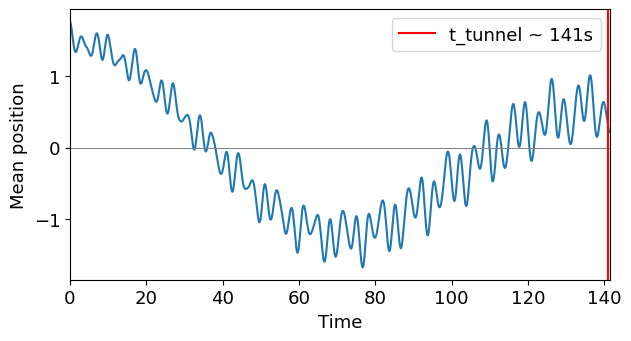

In [11]:
psi = np.load("psi.npy")
prob = np.abs(psi)**2
x_bar = DELTAX * (prob @ x)
# Estimating t_tunnel
t_tunnel = 141
print("The time it takes for one full oscillation, t_tunnel =",t_tunnel)

fig, ax = plt.subplots()
ax.plot(t, x_bar)
ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(t_tunnel, color='red', label='t_tunnel ~ 141s')
ax.legend()
ax.set(xlabel="Time", ylabel="Mean position",
       xlim=(0, t[-1]))
plt.show()

### Check what the mean is telling us

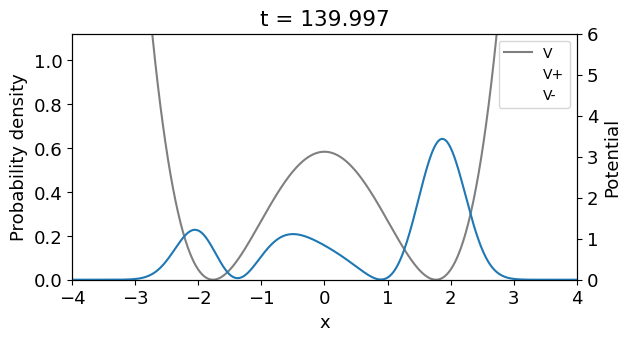

In [12]:
time_view = 140
n = np.argmin(np.abs(t - time_view))
fig, ax = plt.subplots()
ax.plot(x, prob[n])
ax.set(xlabel="x", ylabel="Probability density",
       zorder=1, xlim=(-4, 4),
       ylim=(0, 1.1 * prob.max()),
       title=f"t = {t[n]:.3f}")
ax.patch.set_visible(False)
plot_potentials(ax.twinx(), v_color = ('black', .5), posv_color=('red', 0), negv_color=('blue', 0))
plt.show()

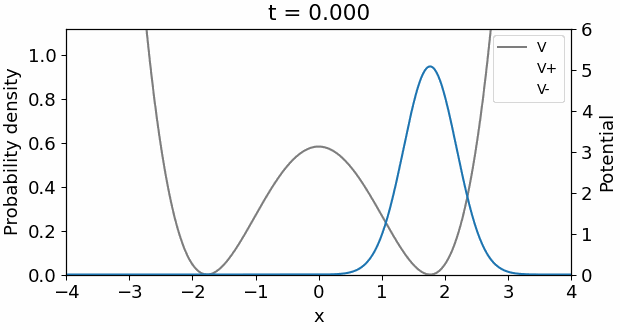

In [13]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

fps = 25
frames = np.unique(np.linspace(0, len(t) - 1, 240, dtype=int))

fig, ax = plt.subplots()
line, = ax.plot(x, prob[0])
ax.set(xlabel="x", ylabel="Probability density",
       zorder=1, xlim=(-4, 4),
       ylim=(0, 1.1 * prob.max()))
title = ax.set_title(f"t = {t[0]:.3f}")

ax.patch.set_visible(False)
plot_potentials(
    ax.twinx(),
    v_color=('black', .5),
    posv_color=('red', 0),
    negv_color=('blue', 0)
)

def update(n):
    line.set_ydata(prob[n])
    title.set_text(f"t = {t[n]:.3f}")
    return line, title

ani = FuncAnimation(
    fig, update, frames=frames,
    interval=1000 / fps, blit=False, repeat=True
)

gif_path = "density_evolution.gif"
ani.save(gif_path, writer=PillowWriter(fps=fps), dpi=100)
plt.close(fig)
display(Image(filename=gif_path))

### Back to Assignment 2

Give the time and mean position at the first major minimum. Use the density at that time to explain whether most of the probability has reached the left well.

For your assigned $\alpha$, check that the run is long enough to see the transfer and return.

Assignment 2 is due Monday, November 2.

## Problem B: Numerical Eigenstates

### (i) **Validate first**

In [14]:
delta_x_view = DELTAX

# Defining the constant
C0 = 1 / (2 * (delta_x_view ** 2))

# Creating the Hamiltonian
main_diag = 2 * C0 * np.ones(ND + 1)
off_diag = -C0 * np.ones(ND)
H_kinetic = sp.diags([off_diag, main_diag, off_diag], [-1, 0, 1], format='csr')
# Creating the potential Hamiltonian for various values of alpha (0.3204, 0.4, and 0.6)
H_potential = sp.diags(V(x, alpha_view), 0, format='csr')
H_potential4 = sp.diags(V(x, 0.4), 0, format='csr')
H_potential6 = sp.diags(V(x, 0.6), 0, format='csr')

H = H_kinetic + H_potential
H4 = H_kinetic + H_potential4
H6 = H_kinetic + H_potential6
# Finding the two lowest energy states and doing problem B (i)
[E0,E1], v = sp.linalg.eigsh(H,k=2,sigma=0,which='LM')
[E0_4,E1_4], v4 = sp.linalg.eigsh(H4,k=2,sigma=0,which='LM')
[E0_6,E1_6], v6 = sp.linalg.eigsh(H6,k=2,sigma=0,which='LM')
print("The two lowest energy eigenstates E0_4 =",E0_4,"and E1_4 =",E1_4,"match λ = α / 4 = 0.4 / 4 = 0.10 and E0_6 =",E0_6,"and E1_6 =",E1_6,"match λ = α / 4 = 0.6 / 4 = 0.15.")

The two lowest energy eigenstates E0_4 = 1.234477237104429 and E1_4 = 1.3469042748710252 match λ = α / 4 = 0.4 / 4 = 0.10 and E0_6 = 1.0624798130297264 and E1_6 = 1.4210435760515032 match λ = α / 4 = 0.6 / 4 = 0.15.


The answers I calculated match the paper's to about 3 or 4 decimal places. We may have used different bounds for *x* and discretized the grid into a different number of points.

### (ii) **Check convergence**

In [15]:
delta_x_view = BOXSIZE / 1200

# Defining the constant for half-spacing and creating new grids
C0_hs = 1 / (2 * (delta_x_view ** 2))
x_hs = np.linspace(-BOXSIZE / 2, BOXSIZE / 2, 1200 + 1)
x_lb = np.linspace(-12 / 2, 12 / 2, 900 + 1)

# Creating the Hamiltonian for half-spacing
main_diag_hs = 2 * C0_hs * np.ones(1200 + 1)
off_diag_hs = -C0_hs * np.ones(1200)
H_kinetic_hs = sp.diags([off_diag_hs, main_diag_hs, off_diag_hs], [-1, 0, 1], format='csr')
H_potential_hs = sp.diags(V(x_hs, alpha_view), 0, format='csr')
H_hs = H_kinetic_hs + H_potential_hs

# Creating the Hamiltonian for a larger box
main_diag_lb = 2 * C0 * np.ones(900 + 1)
off_diag_lb = -C0 * np.ones(900)
H_kinetic_lb = sp.diags([off_diag_lb, main_diag_lb, off_diag_lb], [-1, 0, 1], format='csr')
H_potential_lb = sp.diags(V(x_lb, alpha_view), 0, format='csr')
H_lb = H_kinetic_lb + H_potential_lb

# Finding their lowest energy states
[E0_hs,E1_hs], v_hs = sp.linalg.eigsh(H_hs,k=2,sigma=0,which='LM')
[E0_lb,E1_lb], v_lb = sp.linalg.eigsh(H_lb,k=2,sigma=0,which='LM')
# Printing results
print("E0 on the original grid is",E0,", E1 on the original grid is",E1,", and ΔE on the original grid is",E1-E0)
print("E0 on the half-spaced grid is",E0_hs,", E1 on the half-spaced grid is",E1_hs,", and ΔE on the half-spaced grid is",E1_hs-E0_hs)
print("E0 on the larger box is",E0_lb,", E1 on the larger box is",E1_lb,", and ΔE on the larger box is",E1_lb-E0_lb)

E0 on the original grid is 1.297938110218579 , E1 on the original grid is 1.3402493776573896 , and ΔE on the original grid is 0.04231126743881064
E0 on the half-spaced grid is 1.2979642812850491 , E1 on the half-spaced grid is 1.3402766836388844 , and ΔE on the half-spaced grid is 0.042312402353835266
E0 on the larger box is 1.2979381058660882 , E1 on the larger box is 1.3402493727610747 , and ΔE on the larger box is 0.04231126689498654


The energy eigenstates on the original grid and larger box match to about 7 or 8 digits, while the original grid and half-spaced grid only match to about 4 digits, so likely that is why my results different from the papers. This means that our bounds on *x* are probably wide enough, but we could discretize the grid into more points for extra precision.

### (iii) **Plot eigenfunctions***

Since $\Delta x\sum_{i}|\phi_n x_i|^2=1$, we find $\sqrt{\Delta x}=\frac{1}{\sum_{i}|\phi_n x_i|}$, and φ is normalized by dividing each element by $\sqrt{\Delta x}$.

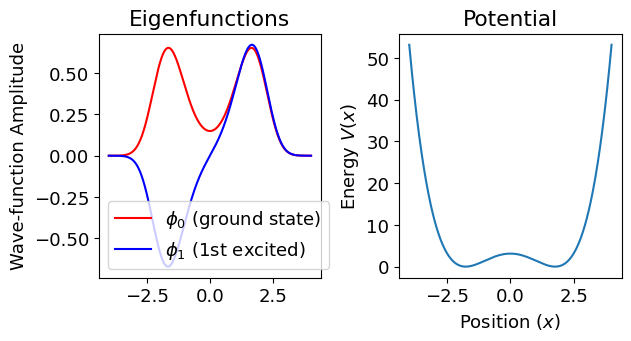

In [16]:
# Normalizing the eigenvectors
phi0 = v[:,0] / np.sqrt(DELTAX)
phi1 = v[:,1] / np.sqrt(DELTAX)
# Checking to make sure that phi0 and the right half of phi1 are positive
if np.sum(phi0) < 0: 
    phi0 = -phi0
# ND is 600, so the midpoint is at 300
if np.sum(phi1[300:]) < 0:
    phi1 = -phi1
# Plotting phi0, phi1, and V(x)
fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True)
# Left panel (Eigenstates)
ax1.plot(x, phi0, label=r'$\phi_0$ (ground state)', color='red')
ax1.plot(x, phi1, label=r'$\phi_1$ (1st excited)', color='blue')
ax1.set_ylabel('Wave-function Amplitude')
ax1.set_title('Eigenfunctions')
ax1.legend(loc='lower left')

# Right panel (Potential)
ax2.plot(x, V(x, ALPHA), label=r'$V(x) = ax^4 - 2x^2 + 1/a$')
ax2.set_xlabel('Position ($x$)')
ax2.set_ylabel('Energy $V(x)$')
ax2.set_title('Potential')
plt.show()

## Problem C: Harmonic-approximation Energies

## Even and odd combinations

The full potential has even and odd energy eigenstates (state functions).
We can write our right-well Gaussian as a sum of even and odd combinations.
This gives us a useful way to understand its motion between the wells.

$$
\psi_{\mathrm S}=\frac{\psi_++\psi_-}{\sqrt{2}},\qquad
\psi_{\mathrm A}=\frac{\psi_+-\psi_-}{\sqrt{2}}.
$$

### Even/odd function refresher
<details class="lab09-answer">
<summary></summary>

Reflecting $x$ swaps the two local Gaussians: $\psi_+(-x)=\psi_-(x)$ and $\psi_-(-x)=\psi_+(x)$. Therefore

$$
\begin{aligned}
\psi_{\mathrm S}(-x)&=\frac{\psi_-(x)+\psi_+(x)}{\sqrt2}=\psi_{\mathrm S}(x),\\
\psi_{\mathrm A}(-x)&=\frac{\psi_-(x)-\psi_+(x)}{\sqrt2}=-\psi_{\mathrm A}(x).
\end{aligned}
$$

The even combination stays the same; the odd combination changes sign.

</details>

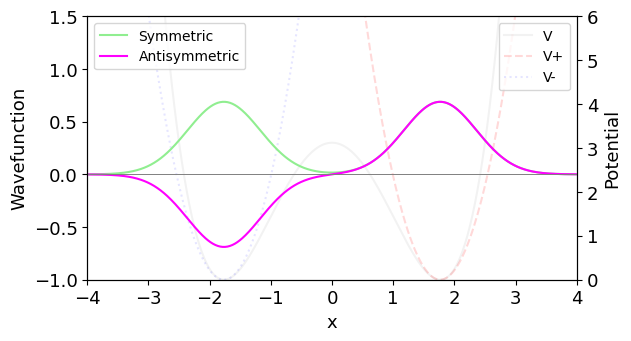

In [17]:
psi_plus = func_psi_0(x, XMIN)
psi_minus = func_psi_0(x, -XMIN)
psi_S = (psi_plus + psi_minus) / np.sqrt(2)
psi_A = (psi_plus - psi_minus) / np.sqrt(2)

fig, ax = plt.subplots()
ax.plot(x, psi_S, label="Symmetric", color='lightgreen')
ax.plot(x, psi_A, label="Antisymmetric", color='magenta')
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="x", ylabel="Wavefunction",
       zorder=1, xlim=(-4, 4), ylim=(-1, 1.5))
ax.legend(loc="upper left", fontsize=10)
ax.patch.set_visible(False)
plot_potentials(ax.twinx(), v_color = ('black', .05), posv_color=('red', .15), negv_color=('blue', .1))
plt.show()

So we've split the right-well Gaussian into pieces whose phases evolve at different rates. Our combinations approximate the lowest even and odd energy eigenstates, $\phi_{\mathrm S}$ and $\phi_{\mathrm A}$. Keeping these two states gives

$$
\Psi(x,t)\approx c_{\mathrm S}\phi_{\mathrm S}(x)e^{-iE_{\mathrm S}t/\hbar}
+c_{\mathrm A}\phi_{\mathrm A}(x)e^{-iE_{\mathrm A}t/\hbar}.
$$

The coefficients come from the initial Gaussian. Both spatial functions can be real; the time factors supply the complex phase. As their relative phase changes, interference moves probability between the wells.
### (i) **Compare energies**

In [18]:
# Finding E_S and E_A
E_S = (psi_S.conj() @ H @ psi_S) / sum(np.abs(psi_S)**2)
E_A = (psi_A.conj() @ H @ psi_A) / sum(np.abs(psi_A)**2)
print("E_S is",E_S,", E_A is",E_A,", and the difference between them E_A - E_S is",E_A-E_S)
print("The relative error |E_S - E0| / |E0| is",np.abs((E_S-E0) / E0),", the relative error |E_A - E1| / |E1| is",np.abs((E_A-E1) / E1),", and the relative error |(E_A-E_S) - ΔE| / |ΔE| is",np.abs(((E_A-E_S) - (E1-E0)) / (E1-E0)))

E_S is 1.4427007978075324 , E_A is 1.4457580109080657 , and the difference between them E_A - E_S is 0.003057213100533307
The relative error |E_S - E0| / |E0| is 0.11153281227297861 , the relative error |E_A - E1| / |E1| is 0.07872313541759944 , and the relative error |(E_A-E_S) - ΔE| / |ΔE| is 0.9277447052382781


The error of $\psi_S$ and $\psi_A$ is around 10%, but the error of the gap between them is almost 1, meaning it is completely inaccurate. This is because the gap is much less than 10% of the energy of either state.

### (ii) **Compare wave function**

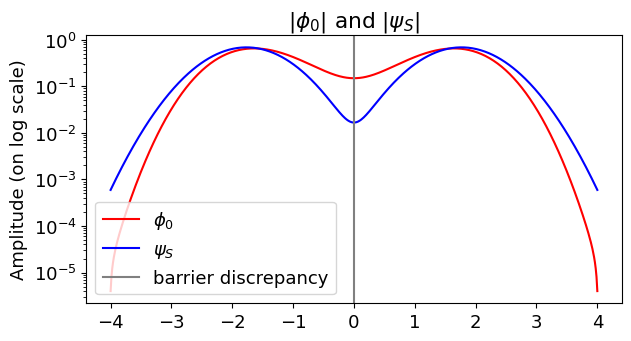

In [19]:
# Normalizing the eigenvectors
psi_S_norm = psi_S / sum(np.abs(psi_S)**2)
# Checking to make sure that psi_S is positive
if np.sum(psi_S) < 0: 
    psi_S = -psi_S
# Plotting phi0, phi1, and V(x)
fig, ax = plt.subplots()
# Left panel (Eigenstates)
ax.semilogy(x, phi0, label=r'$\phi_0$', color='red')
ax.semilogy(x, psi_S, label=r'$\psi_S$', color='blue')
ax.axvline(0, color='gray', label='barrier discrepancy')
ax.set_ylabel('Amplitude (on log scale)')
ax.set_title('$|\phi_0|$ and $|\psi_S|$')
ax.legend(loc='lower left')
plt.show()

The Harmonic-approximation is only good near the wells, but since the 1st excited state has an amplitude of zero near the barrier, ther harmonic-approximation fails to capture that. This is because they are based on two quadratic functions next at the minima.

## Problem D: Compare Evolution Methods

Evolve the new $\psi_0$ from **B**

In [20]:
TD = 2 * np.pi / (E1 - E0)
def psi_D(t):
    return (1 / np.sqrt(2)) * (np.exp(-1j*E0*t)*phi0 + np.exp(-1j*E1*t)*phi1)
print(TD)

148.49910408063647


***Write to results.json***

In [22]:
import json

results = {
"tsn": "200075102",
"alpha": ALPHA,
"x_mean_pi": x_bar.tolist(),
"t_tunnel": float(t_tunnel),
"E0": float(E0), "E1": float(E1),
"phi0": phi0.tolist(), "phi1": phi1.tolist(),
"E_S": float(E_S), "E_A": float(E_A),
}
with open("results.json", "w") as f:
    json.dump(results, f)

### AI Use Appendix

Mostly used Google AI search. [Link](https://www.google.com/search?client=firefox-b-1-d&q=centered+3-point+matrix&fbs=ACAhTvwdifjn2dKXmjtOfBxVFl_koHVe5RLSnJlTH2QYaq_YVdbYfq_upmJPcFgYr-v9gSSwwUS9BWFZgSEzQrpytaWqmaG30yxr8giaVV35cwMZ-gLQDM9VwAJxj1tSKETw7UA-syKMRiMQVYtDgLQl3rbM9vqCnzRvTY_NbLtajlN3KxRuVAU8RlQK0Hpdo4jzlfJm6KVbZ4XJ8Ck79QEaX8gyTP42Zg&aep=10&ntc=1&sxsrf=AKL5yDi8LcGrKTyYfUQafzCCCC9Pd9RY7g%3A1793993716466&mstk=AUtExfDER7Z9xEG3uSUfkdIIh391EuqwF5AJaUFL5Tt1kESKuOYyF_8S1VnUU51OHFFBtDtexLw_xGfcHR-UbOOavf4CwjA1i19OIjLmCFjpXaz8ZgZIBzbMXE2k-z6BgfH02nU1EhfiBa0WmZl6dWVwZXb8GMzzpBr0EXTXz9-n-H0JUFluhHvjloYub0qBep8lLVBQjO2cXefISQbzzPgoPT4kzoCG8MWSuRB1BA-LTGKUmWx6BhQa-jM00JAs_EkCaILNj7KbNNIUtVMhsn_5p0x8rRRPiLDs3iU&aioh=3&csuir=1&mtid=9CvuapOzMIbSgLQPhuSpaA&udm=50)